# Single window analysis

Change the settings and **Run All**. Code lives next to this notebook:

| file | what |
|---|---|
| `window.py` | load data, rule check per candle, trades in the window |
| `chart.py` | the plotly figure |
| `tables.py` | styled tables |
| `theme.py` | design: colors, EMA list, zone colors, layout |

**EMA test (`EMA_SET`):** `'9_21_200'` uses EMA 9/21/200, `'13_48_200'` uses EMA 13/48/200 - never both at the same time.

**Momentum (docs/ema.md, 15m):** fast > middle > 200 = BULL · 200 > middle > fast = BEAR · middle EMA (21 or 48) flat (moved < 0.25 ATR in 2h) or not in the middle = NONE

**Entry (docs/entry.md):** on each completed 5m candle → **BULL = BUY**, **BEAR = SELL**, **NONE = no entry**.
**BLOCKED** if the close is on the wrong side of the fast EMA (EMA9 or EMA13): distance (close − fast EMA) / ATR 5m negative for a buy, positive for a sell. Enter at the next candle's open.

**Stop loss (docs/stop_loss.md):** −20% stop, raise the stop 10% for every +10%, take profit +50% (position %, at `LEVERAGE`).

`OVERLAP = True`: every momentum candle opens its own trade (many trades per window).
`OVERLAP = False`: one trade at a time, signals while in a trade are skipped.

Zones are drawn on the chart as information only - they do not filter the entry.

In [93]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, '..')              # project root: stop_loss.py, zone_create.py, data/

from analysis.window import build_window
from analysis import tables, chart

# ---------------- settings ----------------
SYMBOL      = 'BTCUSDT'
START       = '2024-12-05 00:55'      # first candle (UTC)
CANDLES     = (180, 210)                # candle range from START: (30, 60) = candle 30 to 59 | or a number, e.g. 30
LEVERAGE    = 10                      # 10x -> stop -2%, trail step 1%, take profit +5% in price
MARGIN_USDT = 100                     # $ per trade for P&L
EMA_SET     = '13_48_200'              # '9_21_200' or '13_48_200' (never both)
OVERLAP     = True                    # True: trade every momentum candle | False: one trade at a time
HIGHLIGHT   = 1                       # trade # drawn with full stop / TP detail (None = none)
SHOW_ZONES  = ['15m', '1h']           # add '4h', '1d'
# ------------------------------------------

win = build_window(SYMBOL, START, CANDLES, LEVERAGE, OVERLAP, EMA_SET)
print(f"{SYMBOL}: {win.w['open_time'].iloc[0]} -> {win.w['open_time'].iloc[-1]}  ({len(win.w)} candles)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
BTCUSDT: 2024-12-05 15:55:00+00:00 -> 2024-12-05 18:20:00+00:00  (30 candles)


## 1. Rules for each candle

In [94]:
tables.rules(win)

EMA test 13_48_200 | momentum: {'NONE': 26, 'BULL': 4} | state: {'NO ENTRY': 26, 'BLOCKED': 4}


,time,open,high,low,close,EMA 13>48>200,EMA 200>48>13,EMA48 slope,EMA48 flat,MOMENTUM,EMA13 slope,EMA13 slope ok,close-EMA13 (ATR),distance ok,touch EMA48,ENTRY,STATE
0,12-05 15:55,101536.03,101595.83,101268.64,101292.01,✔,✘,0.40,✘,BULL,-0.37,✘,-2.96,✘,✘,-,BLOCKED
1,12-05 16:00,101292.00,101910.09,101284.65,101668.00,✔,✘,0.27,✘,BULL,-0.32,✘,-1.68,✘,✘,-,BLOCKED
2,12-05 16:05,101667.99,101779.15,101272.00,101578.10,✔,✘,0.27,✘,BULL,-0.32,✘,-1.86,✘,✘,-,BLOCKED
3,12-05 16:10,101578.10,101653.73,101358.05,101453.99,✔,✘,0.27,✘,BULL,-0.32,✘,-2.18,✘,✘,-,BLOCKED
4,12-05 16:15,101453.99,101994.20,101439.79,101891.70,✔,✘,0.18,✔,NONE,-0.24,✘,-0.91,✘,✘,-,NO ENTRY
5,12-05 16:20,101891.69,101999.00,101800.00,101800.00,✔,✘,0.18,✔,NONE,-0.24,✘,-1.16,✘,✘,-,NO ENTRY
6,12-05 16:25,101800.00,101800.01,101272.00,101272.01,✔,✘,0.18,✔,NONE,-0.24,✘,-2.30,✘,✘,-,NO ENTRY
7,12-05 16:30,101272.01,101403.82,101142.82,101142.82,✔,✘,0.08,✔,NONE,-0.24,✘,-2.33,✘,✘,-,NO ENTRY
8,12-05 16:35,101142.83,101142.83,100568.02,100607.99,✔,✘,0.08,✔,NONE,-0.24,✘,-3.46,✘,✘,-,NO ENTRY
9,12-05 16:40,100607.99,101176.47,100607.99,101176.47,✔,✘,0.08,✔,NONE,-0.24,✘,-2.16,✘,✘,-,NO ENTRY


## 2. Trades (stop-loss rules)

In [95]:
tables.trades(win, MARGIN_USDT)

No trade in this window (no momentum) - move START and re-run.


## 3. Chart

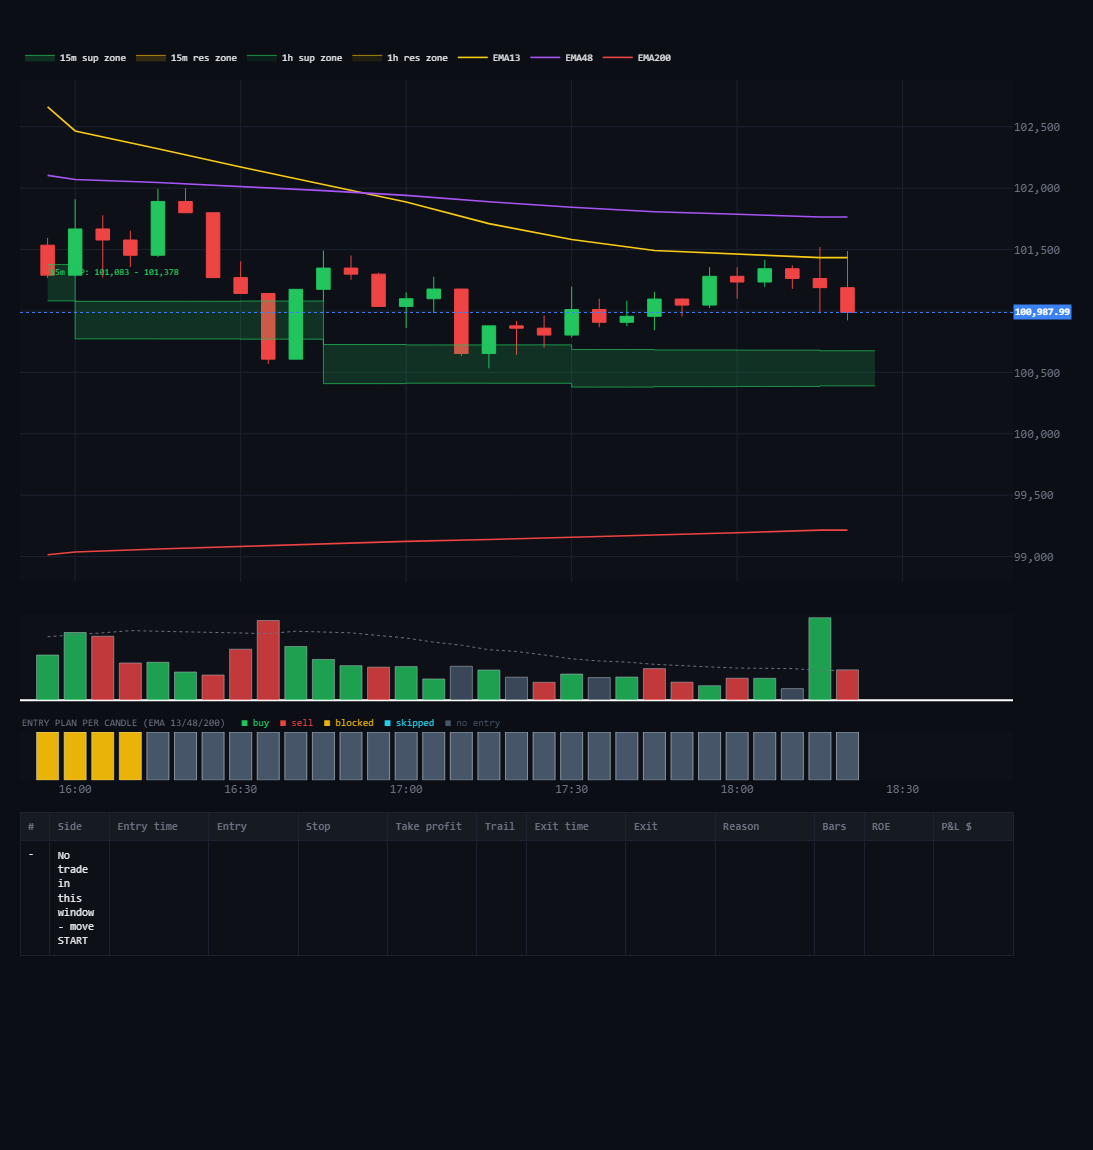

In [96]:
chart.plot_window(win, MARGIN_USDT, SHOW_ZONES, HIGHLIGHT).show()